# AP 155 Lab Exercise
---
## Exercise 11: Fourier transform

_Instructions_:
- **Report**: See instructions in Problems 1,2,3
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Luarez, Karl Andrei
- _Student No._: 2024-12430
- _Section_: THR-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

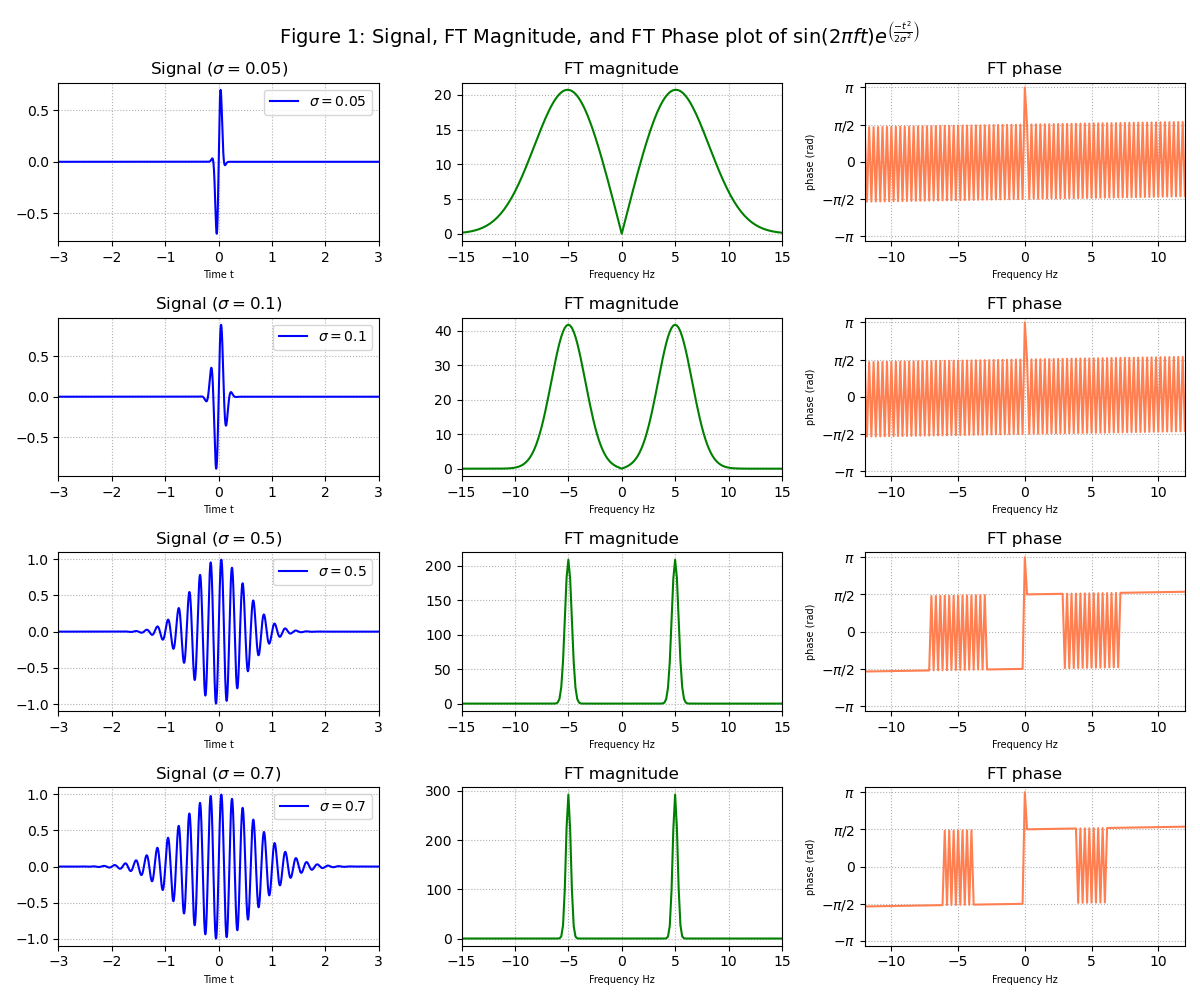
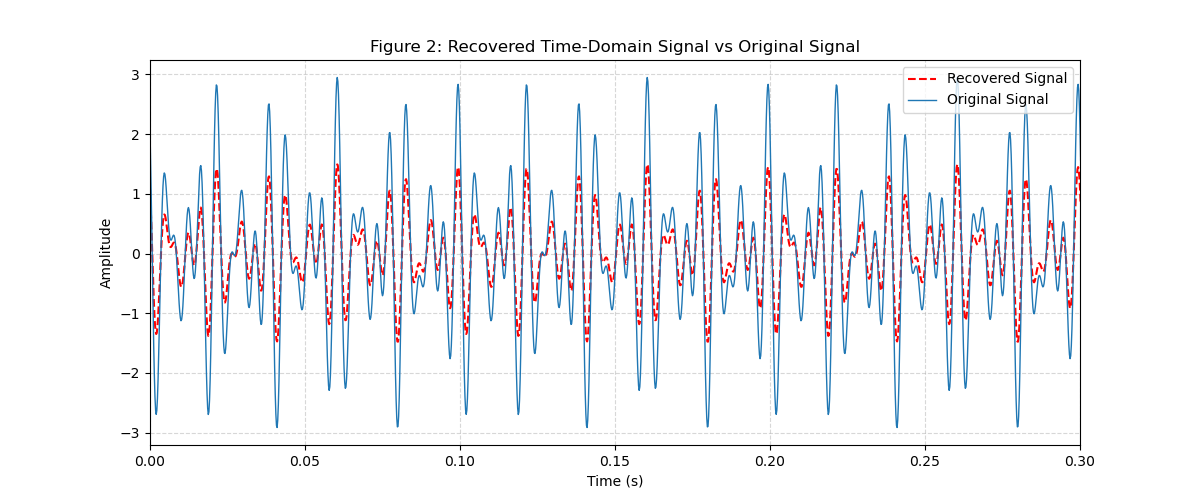
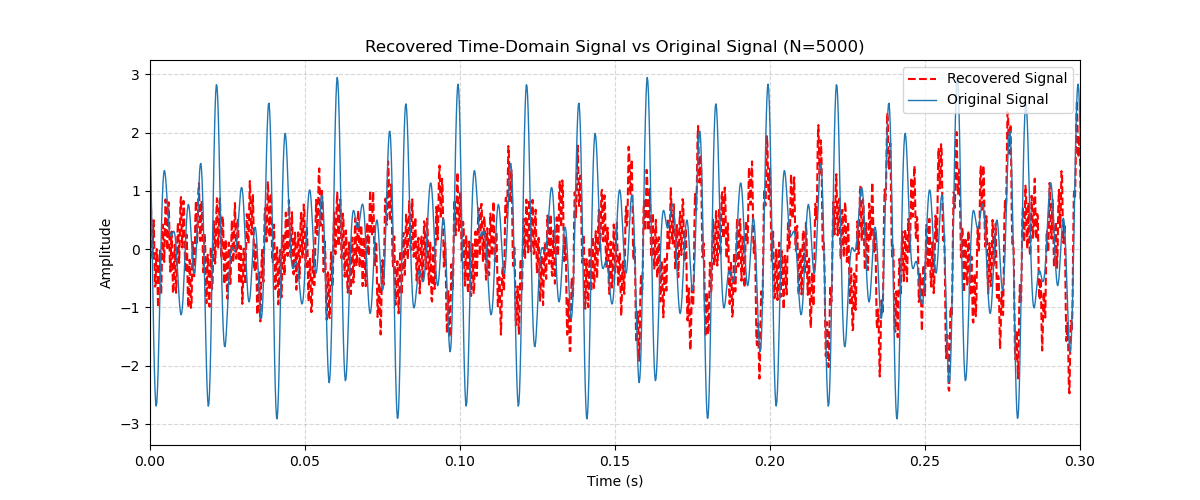
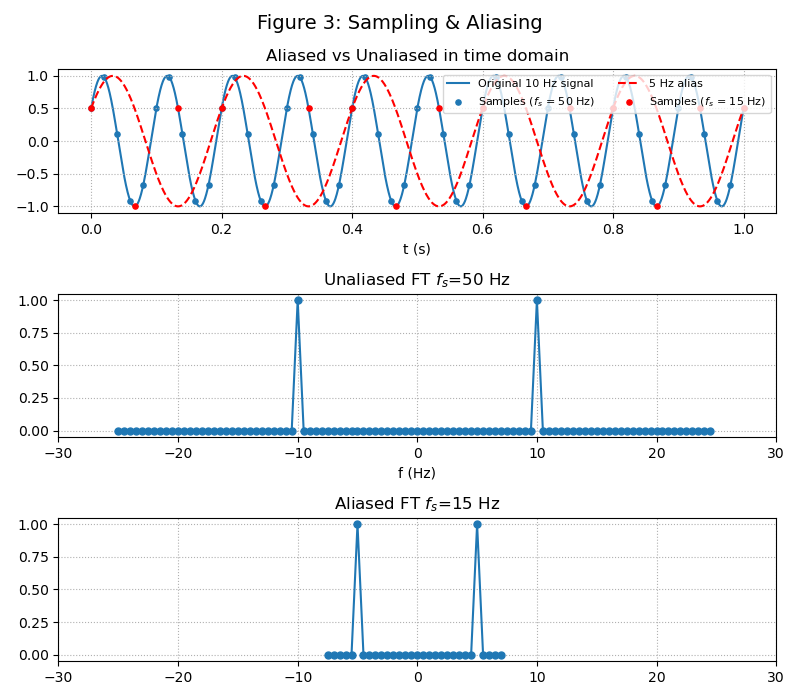



### Report discussion

1. Fig. 1 shows that expanding the standard deviation $\sigma$ expands the width of the Gaussian envelope in the time domain, allowing more cycles of the sine wave. Consequently, this causes its fourier transform magnitude to become narrower and peak at the carrier frequency $f=5.0 Hz$ and the phase vibrations become concentrated at $f$. Decreasing $\sigma$ does the opposite and causes the magnitude and phase oscillations to become broader.

2. For signal processing in 1D, Figure 2 compares the original signal and recovered signal. Lowering $N (>25000)$ for fixed $dt$ reduces the record (since $T = Ndt$) as a consequence this lowers the gap between frequency bins, thus reducing resolution. Lowering $N$ causes the peak magnitude to decrease relative to the noise. The original signal can still be recoverable but this slowly fails as you go down in $N$ such as the $N=500$ shown in the Problem 2 report figure.

3. Fig 3 compares the effect of sampling a continous signal below the Nyquist rate $(f_{nyquist}=2f_s = 20Hz)$. When sampled above $f_{nyquist}$, the sampled points are enough to reconstruct the original $f_0 = 10Hz$ signal, as shown in the unaliased fourier transform peaking at $\pm f_0$. However, sampling below this produces lower samples which are too far apart which misplaces the FT peaks at $5Hz$ instead making the recovered signal have longer cycles and appears out of phase compared to the original signal.

### Other comments
- No comments


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Exploring FT of varying waveforms

Given the waveforms from the pool below, produce a $1\times3$ plot containing the following: 
1) the signal, with its variations, 
2) the magnitude of its Fourier transform, and 
3) the phase information of the transform (up to you if unwrapped or not). 
    
Discussion: 2-3 sentences explaining how changing the shape of the input signal affects it transform. 
Ex: for the Gaussian waveform, how does it Fourier transform change based on increasing or decreasing sigma?

Waveforms you can try (prefarably non-sinusoidal):
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function (vary sigma)
- Finite-time sinusoid
- Gaussian wave packet
- Dirac-delta 

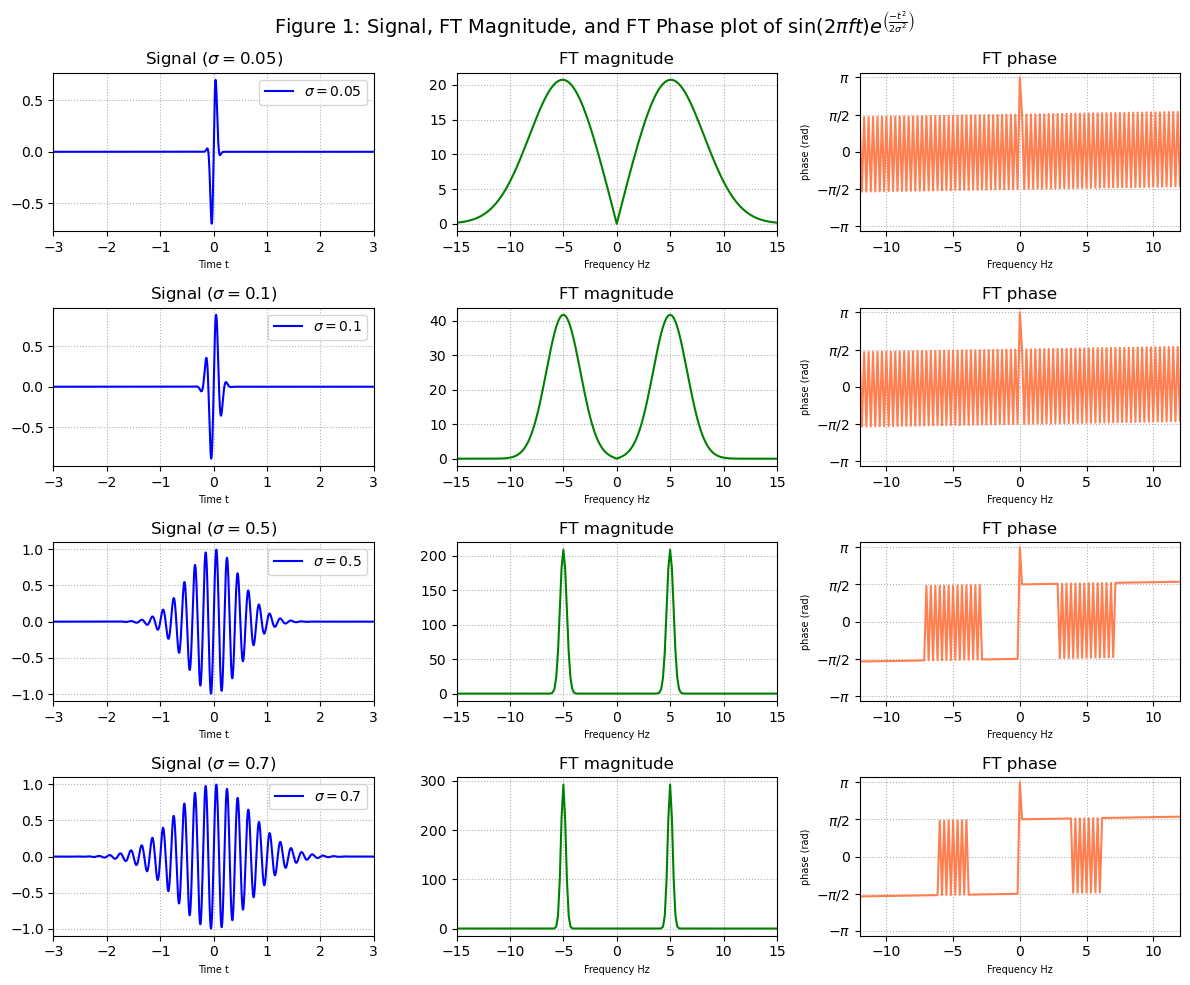

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Gaussian wave packet parameters
t = np.linspace(-3, 3, 2001)
dt = t[1] - t[0]
freq_ft = np.fft.fftshift(np.fft.fftfreq(len(t), dt))
wp_freq = 5
wp_sigmas = [0.05, 0.1, 0.5, 0.7]

# Create a figure with n rows and 3 columns (n = no. of sigmas)
fig, axs = plt.subplots(len(wp_sigmas), 3, figsize=(12, 2.5 * len(wp_sigmas)))

for i, s in enumerate(wp_sigmas):
    wave_packet = np.sin(2 * np.pi * wp_freq * t) * np.exp(-(t**2) / (2 * s**2))
    label = fr'$\sigma = {s}$'
    
    ax_t, ax_f, ax_p = axs[i]

    # Signal plot
    ax_t.plot(t, wave_packet, label=label, color='blue')
    ax_t.set_title(f"Signal ({label})")
    ax_t.set_xlim(-3, 3)
    ax_t.set_xlabel("Time t", fontsize=7)
    ax_t.grid( linestyle=':')
    ax_t.legend(loc="upper right")

    # fft magnitude plot
    ft_signal = np.fft.fftshift(np.fft.fft(wave_packet))
    ft_mag = np.abs(ft_signal)
    ax_f.plot(freq_ft, ft_mag, color='green')
    ax_f.set_title("FT magnitude")
    ax_f.set_xlim(-15, 15)
    ax_f.set_xlabel("Frequency Hz", fontsize=7)
    ax_f.grid( linestyle=':')

    # 3. phase plot
    phase = np.angle(ft_signal)
   
    ax_p.plot(freq_ft, phase, color='coral')
    ax_p.set_title("FT phase")
    ax_p.set_xlim(-12, 12)
    ax_p.set_ylim(-np.pi - 0.2, np.pi + 0.2)
    ax_p.set_yticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
    ax_p.set_yticklabels([r"$-\pi$", r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$"])
    ax_p.set_xlabel("Frequency Hz", fontsize=7)
    ax_p.set_ylabel("phase (rad)", fontsize=7)
    ax_p.grid(linestyle=':')

fig.suptitle(r'Figure 1: Signal, FT Magnitude, and FT Phase plot of $\sin(2\pi ft)e^{\left(\frac{-t^2}{2\sigma^2}\right)}$', fontsize = 14)
plt.tight_layout()
plt.savefig("Figures/Exercise 10 Figure 1.png")
plt.show()

### Problem 2: Signal Processing in 1D (Fill in the blanks/Code to get to the desired result)

Steps performed: 

1) Create a composite signal from multiple sinusoids with three frequencies, get fft of clean signal
2) Add noise (gaussian noise)
3) Add a window (Hann)
4) Get fft of the noisy signal
5) filter frequencies below a threshold
6) get the inverse fft
7) compare the result

Discussion: Try running the procedure with a lower number of N (N<25000). What does lowering N do to the original signal? Will I still be able to recover that original signal if I add the noise below? Is there a limit of N to which I can recover the signal well? Why? (Answer in ~3 sentences)


In [3]:
#Make a wave (cosine or sine) - you can do combo of waves
N = 25000
dt = 0.0002 #if spacing is 0.0002, then frequency is 5000 Hz 
t_ = np.arange(N)*dt
freqs = [130, 230, 180]
phase = [np.pi/3, np.pi/4, np.pi/6]


signal_original = np.sum([np.cos(2*np.pi*f*t_ + p) for f, p in zip(freqs, phase)], axis=0)

(0.0, 0.3)

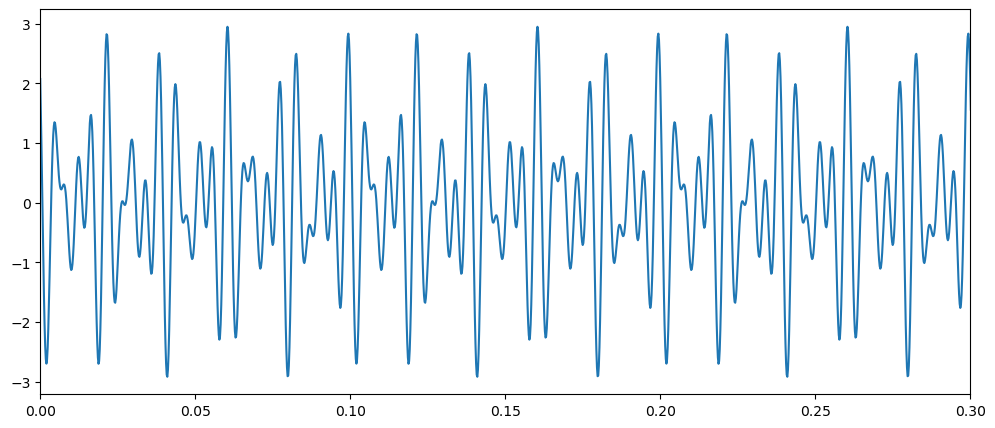

In [4]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, signal_original)
ax.set_xlim(0,0.3)

Text(0.5, 1.0, 'Fourier Transform of the original signal')

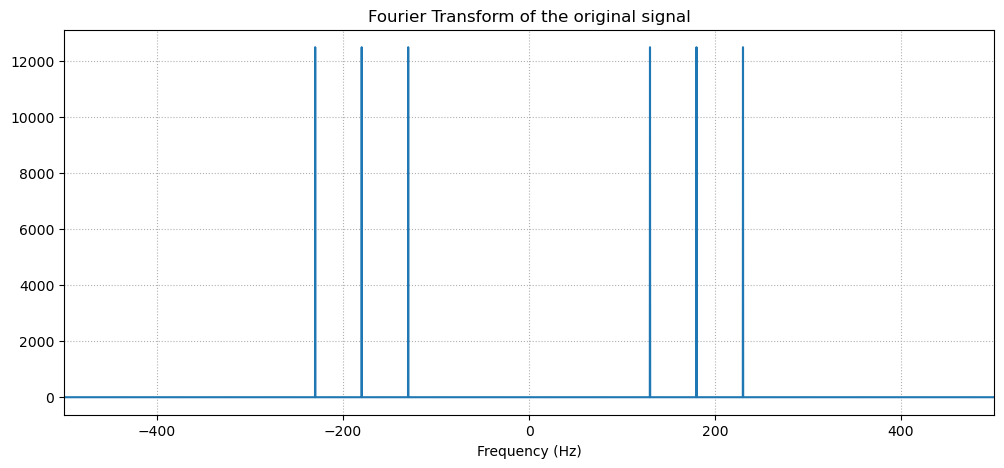

In [5]:
#FILL: Plot the fourier transform of the clean, original signal

originalsignal_fft = np.fft.fftshift(np.fft.fft(signal_original))
originalsignal_freqs = np.fft.fftshift(np.fft.fftfreq(N, dt))

fig, ax = plt.subplots(figsize= (12,5))
ax.plot(originalsignal_freqs, np.abs(originalsignal_fft))
ax.set_xlim(-500,500)
ax.set_xlabel("Frequency (Hz)")
ax.grid(True, linestyle=':')
ax.set_title("Fourier Transform of the original signal")

In [6]:
rng = np.random.default_rng()

#Define parameters of Gaussian noise)
mean = 0
std = 2

noise = rng.normal(loc = mean, scale = std, size = len(t_)) #Add noise to every data point
#Noisy data here
noisy_data = signal_original + noise*5

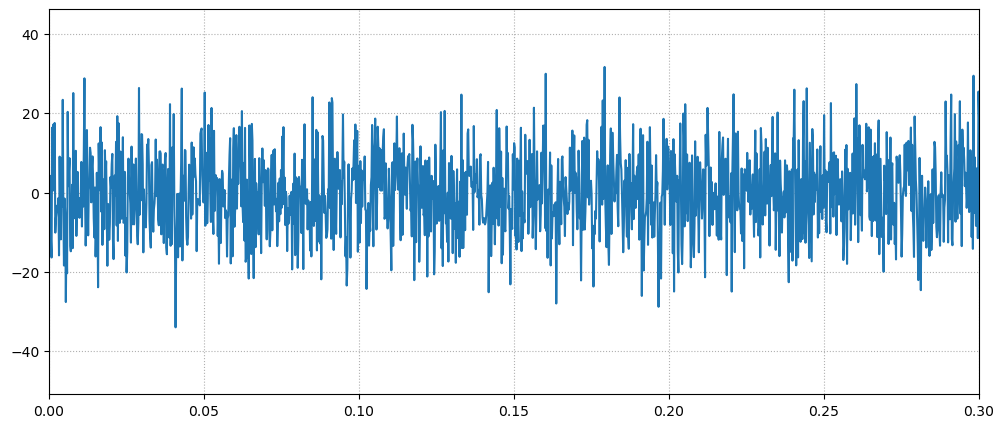

In [7]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, noisy_data)
ax.set_xlim(0,0.3)
ax.grid(True, linestyle=':')

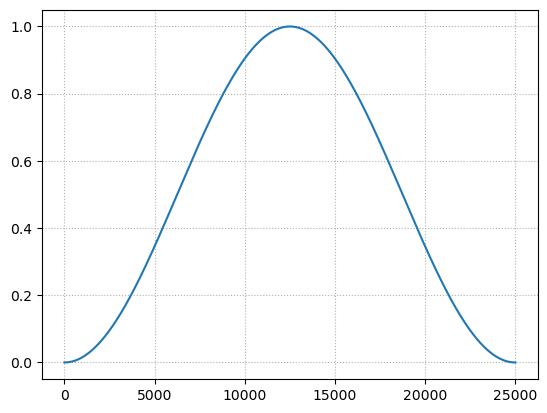

In [8]:
window = np.hanning(len(noisy_data)) #Create a window the size of the data length
plt.plot(window)
plt.grid(True, linestyle=":")

In [9]:
#fourier of hanning window
windowSigPeaks = np.abs(np.fft.fftshift(np.fft.fft(window)))
windowSigFreqs = np.fft.fftshift(np.fft.fftfreq(N, dt))


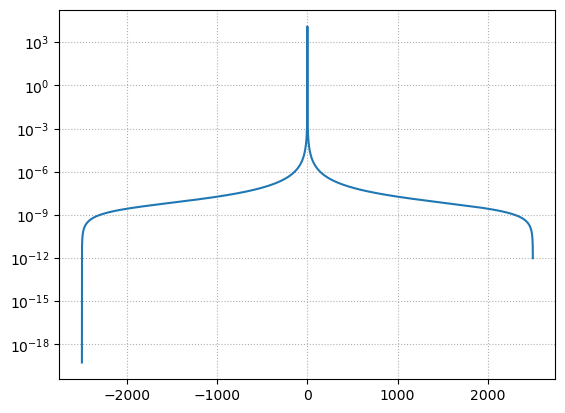

In [10]:
plt.plot(windowSigFreqs, windowSigPeaks)
plt.yscale('log')
plt.grid(True, linestyle=':')

In [11]:
noisyFourier = np.fft.fft(noisy_data*window)
noisySigPeaks = np.abs(np.fft.fftshift(np.fft.fft(noisy_data*window)))


(-500.0, 500.0)

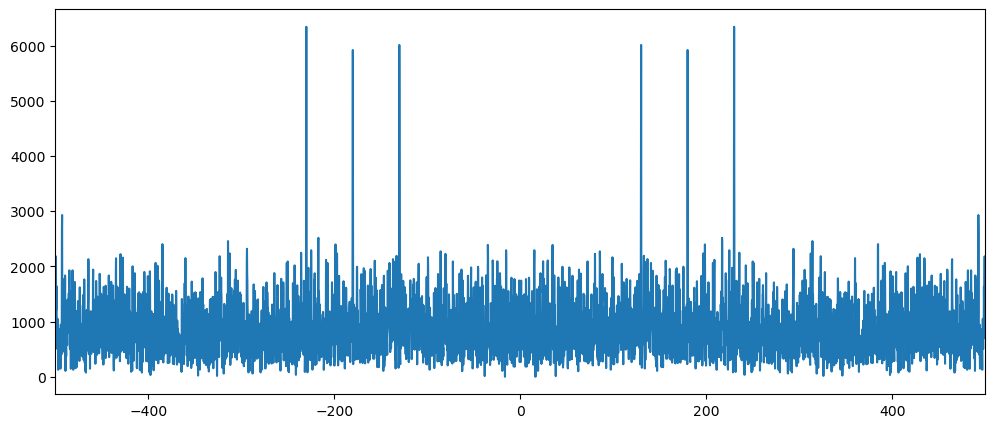

In [12]:
# Fill: Plot the magnitude of fourier transform of the noisy data multiplied by the hanning window

noisy_freqs = np.fft.fftfreq(N, dt)
fig, ax = plt.subplots(figsize = (12,5))
ax.plot(np.fft.fftshift(noisy_freqs), noisySigPeaks)
ax.set_xlim(-500,500)

In [13]:
# Fill: Find a suitable threshold value to filter the noise in fourier space
fourier_mag = np.abs(noisyFourier)
thresholds = np.linspace(0, np.max(fourier_mag), 1000)

rmse_values = []

for T in thresholds:
    # Zero out bins below threshold
    filtered_fft = np.where(fourier_mag >= T, noisyFourier, 0)

    # Calculate RMSE 
    recovered = np.fft.ifft(filtered_fft).real
    rmse = np.sqrt(np.mean((recovered - signal_original)**2))

    rmse_values.append(rmse)

# Extract optimal threshold & minimum error
best_index = np.argmin(rmse_values)
best_threshold = thresholds[best_index]
minimum_rmse = rmse_values[best_index]

print(f"Best Threshold : {best_threshold:8.1f}")
print(f"Minimum RMSE : {minimum_rmse:8.4f}")


Best Threshold :   3966.1
Minimum RMSE :   0.6390


In [14]:
# Fill: with the cleaned signal in fourier space, convert it back to the time domain

# Applying the threshold to filter noise in the Fourier domain
filtered_fft = np.where(np.abs(noisyFourier) >= best_threshold, noisyFourier, 0)
cleaned_signal = np.fft.ifft(filtered_fft).real

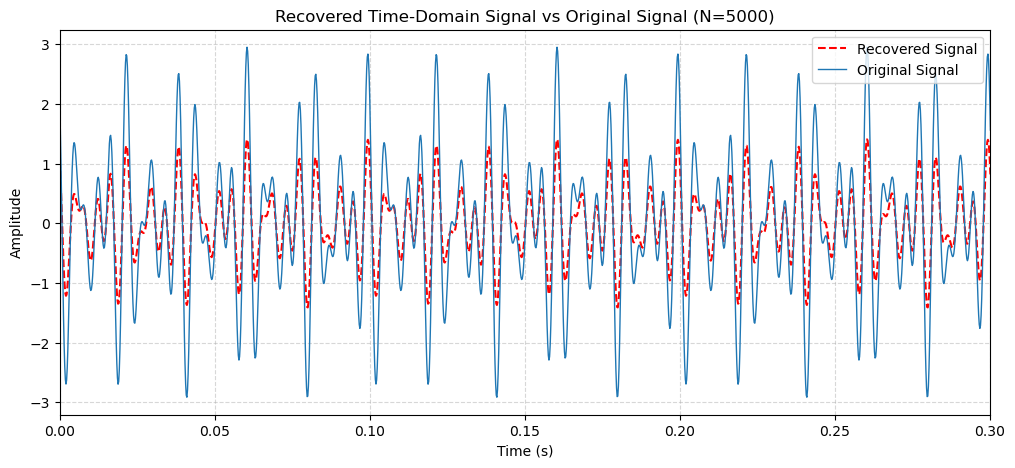

In [15]:
# Plot the recovered signal
# fig, ax = plt.subplots(figsize= (12,5))
# ax.plot(t_, recoveredSignal)
# ax.set_xlim(0,0.3)

recoveredSignal = cleaned_signal

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(t_, recoveredSignal, 'r--', label="Recovered Signal", lw=1.5)
ax.plot(t_, signal_original, lw=1, label="Original Signal")

ax.set_xlim(0, 0.3)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Amplitude")
ax.set_title("Recovered Time-Domain Signal vs Original Signal (N=5000)")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper right")

plt.savefig("Figures/Exercise 10 Figure 2 (lower N.png")
plt.show()

### Problem 3: Aliasing
1) Using different sampling frequencies (uniform sampling), generate a sinusoidal signal. Note the sampling frequencies, and the signal frequency. Use a sampling frequency above the Nyquist frequency, and another one below it.
3) Get their fourier transforms. Are they the same?
4) Plot: Show the fourier transform of an aliased signal, how it looks like in the time-domain, and how the actual signal looks like in the time domain if it's not aliased.
   
Discussion: Explain the report figure. Note the frequency of the signal you wanted to sample, the sampling frequencies used for the aliased and the non-aliased wave

### 

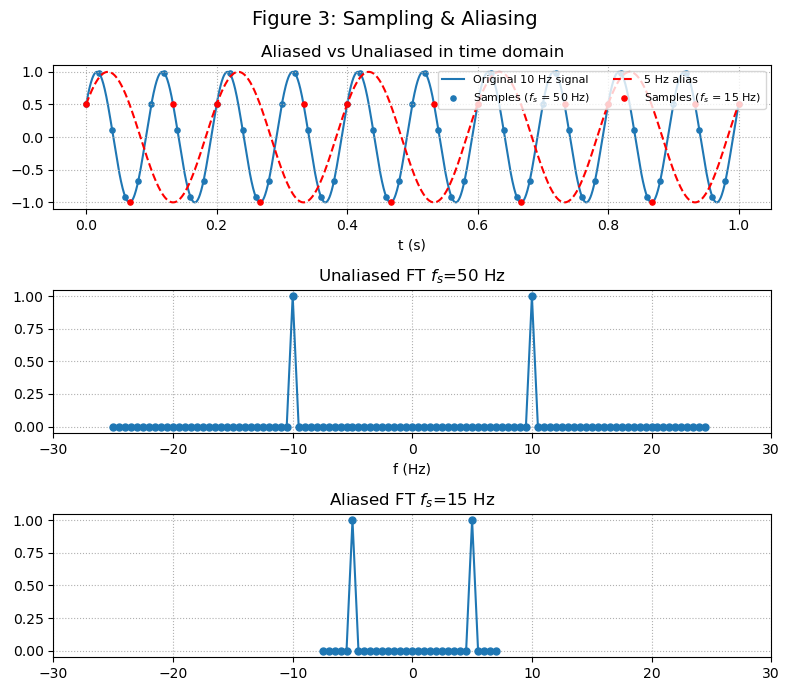

In [37]:
f_signal = 10  # Hz
f_nyquist = 2 * f_signal  # 20 Hz
phi = np.pi / 6
duration = 2  # s
f_over = 50  # unaliased
f_under = 15  # aliased

def fft_sampling(freq):
    n = int(duration * freq)
    t = np.arange(n) / freq
    y = np.sin(2 * np.pi * f_signal * t + phi)
    fft_f = np.fft.fftshift(np.fft.fftfreq(n, 1/freq))
    fft_y = np.abs(np.fft.fftshift(np.fft.fft(y))) * 2 / n
    return t, y, fft_f, fft_y

t_above, y_above, fft_f_above, fft_y_above = fft_sampling(f_over)
t_below, y_below, fft_f_below, fft_y_below = fft_sampling(f_under)

t_plot = np.linspace(0, 1, 2001)
real_signal = np.sin(2 * np.pi * f_signal * t_plot + phi)

f_alias = np.abs(f_signal - f_under * round(f_signal / f_under))  # 5 Hz alias
alias = np.sin(2 * np.pi * f_alias * t_plot + phi)

fig, ax = plt.subplots(3, figsize=(8, 7))

#restrict t to be <=1
m_above = t_above <= 1 
m_below = t_below <= 1

# Signal plot
ax[0].plot(t_plot, real_signal, label=f"Original {f_signal} Hz signal", zorder =0)
ax[0].scatter(t_above[m_above], y_above[m_above], s = 14, label=f"Samples ($f_s$ = {f_over} Hz)", zorder =1) #unaliased samples
ax[0].plot(t_plot, alias, "r--", label=f"{f_alias} Hz alias")
ax[0].scatter(t_below[m_below], y_below[m_below], color='r', s=14, label=f"Samples ($f_s$ = {f_under} Hz)", zorder =2) #aliased
ax[0].set_title('Aliased vs Unaliased in time domain')
ax[0].legend(loc="upper right", fontsize=8, ncol=2)
ax[0].grid(linestyle = ":")
ax[0].set_xlabel('t (s)')

# unaliased ft
ax[1].plot(fft_f_above, fft_y_above, "-o", ms=5)
ax[1].set_title(f'Unaliased FT $f_s$={f_over} Hz')
ax[1].set_xlabel('f (Hz)')
ax[1].grid(linestyle = ":")
ax[1].set_xlim(-30,30)

# aliased ft
ax[2].plot(fft_f_below, fft_y_below, "-o", ms=5)
ax[2].set_title(f'Aliased FT $f_s$={f_under} Hz')
ax[2].grid(linestyle = ":")
ax[2].set_xlim(-30,30)


fig.suptitle("Figure 3: Sampling & Aliasing", fontsize=14)
fig.tight_layout()
plt.savefig("Figures/Exercise 10 Figure 3.png")
plt.show()


#### Problem code summary

The code uses the numpy.fft module to compute the discrete forier transform using of functions using the fast fourier transform (fft) algorithm. This module was used to construct a function that plots the magnitude, and phase of a fourier transform given a signal and its parameters, signal processing and recovery in 1D and demonstration of aliasing in time and frequency domains for undersampling.

---
## Section 3: Notes

In [17]:
import numpy as np
import matplotlib.pyplot as plt

### Fourier transform (from $t$-space to $\omega$-space)
$$ Y(\omega) = \int_{-\infty}^{+\infty} dt \frac{e^{-i\omega t}}{\sqrt{2\pi}}y(t)$$

### Inverse Fourier transform (from $\omega$-space to $t$-space)
$$ y(t) = \int_{-\infty}^{+\infty} d\omega Y(\omega) \frac{e^{i\omega t}}{\sqrt{2\pi}}$$

Something to think about: while we essentially do numerical integration, we do not impose h. Instead, we utilize the spacing of the dataset.

### Discrete FT/IFT

$$ Y_n = \frac{1}{\sqrt{2\pi}} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{y_k\}  +\sin(nk\theta)\Im\{y_k\} +i(\cos(nk\theta)\Im\{y_k\} −\sin(nk\theta)\Re\{y_k\})]\right]$$

$$ y_k = \frac{\sqrt{2\pi}}{N} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{Y_n\}  -\sin(nk\theta)\Im\{Y_n\} +i(\cos(nk\theta)\Im\{Y_n\} +\sin(nk\theta)\Re\{Y_n\})]\right]$$

Why bother it doing this way? 

It cleanly splits the real and imaginary part for both inputs and outputs, so that you can use a pair of floats rather than an aggregate complex data type (complex128 is just a pair of float64 anyway).

Using $Z=e^{−i\theta}, \rightarrow Z^{\pm nk} = e^{\mp ink\theta} = \cos(nk\theta)\mp i\sin(nk\theta)$.

(0.0, 4.0)

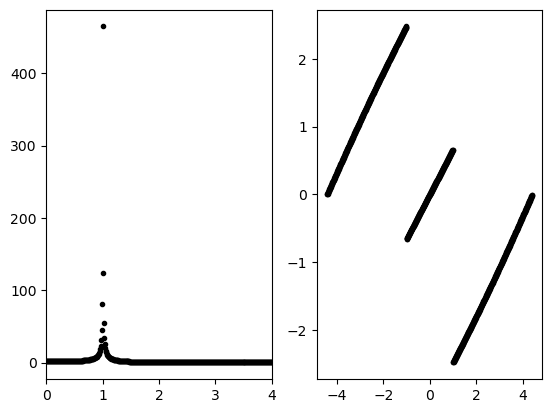

In [18]:
import numpy as np
import matplotlib.pyplot as plt

N = 1000
x = np.linspace(0, 18*2*np.pi, N)
deltaT = x[1] - x[0]

f = 1
y = np.cos(2*np.pi*f*x)

freqs = np.fft.fftfreq(N, deltaT)
Yk = np.fft.fft(y)

# # Q: Why do fftshift?
# Yk = np.fft.fftshift(Yk)

Yk_mag = np.abs(Yk)
Yk_phase = np.angle(Yk)
# Q: Why unwrap?
Yk_phase = np.unwrap(Yk_phase)

fig, ax = plt.subplots(1,2)

ax[0].plot(freqs, Yk_mag, "k.")
ax[1].plot(freqs, Yk_phase, "k.")
ax[0].set_xlim(0, 4)

### Waveforms of interest
- Sinusoid (single frequency, varying phase shift)
- Sum of sinusoids with different frequencies and phases
- Product of sinusoids with different frequencies and phases
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function
- Finite-time sinusoid
- Gaussian wave packet

In [19]:
t = np.linspace(0,10,1000) #Create 100 pts from 0 to 10
x = np.sin(2*np.pi*2*t)

Text(0, 0.5, 'x')

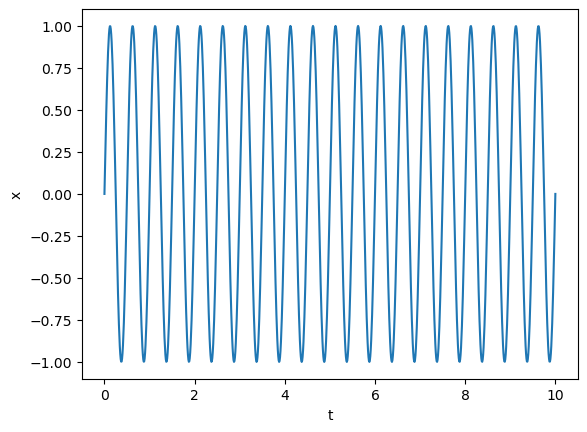

In [20]:
plt.plot(t,x)
plt.xlabel("t")
plt.ylabel("x")

In [21]:
x_ft = np.fft.fft(x)
np.fft.fftfreq?

Signature: np.fft.fftfreq(n, d=1.0)
Docstring:
Return the Discrete Fourier Transform sample frequencies.

The returned float array `f` contains the frequency bin centers in cycles
per unit of the sample spacing (with zero at the start).  For instance, if
the sample spacing is in seconds, then the frequency unit is cycles/second.

Given a window length `n` and a sample spacing `d`::

  f = [0, 1, ...,   n/2-1,     -n/2, ..., -1] / (d*n)   if n is even
  f = [0, 1, ..., (n-1)/2, -(n-1)/2, ..., -1] / (d*n)   if n is odd

Parameters
----------
n : int
    Window length.
d : scalar, optional
    Sample spacing (inverse of the sampling rate). Defaults to 1.

Returns
-------
f : ndarray
    Array of length `n` containing the sample frequencies.

Examples
--------
>>> signal = np.array([-2, 8, 6, 4, 1, 0, 3, 5], dtype=float)
>>> fourier = np.fft.fft(signal)
>>> n = signal.size
>>> timestep = 0.1
>>> freq = np.fft.fftfreq(n, d=timestep)
>>> freq
array([ 0.  ,  1.25,  2.5 , ..., -3.75, -2.5 , -1

### Plotting

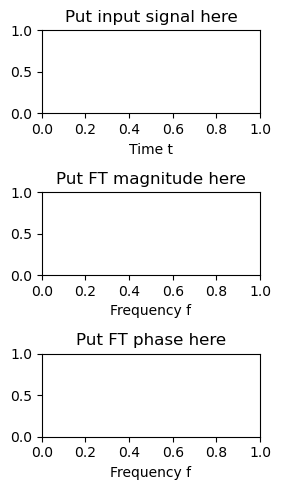

In [22]:
fig, ax = plt.subplots(3, 1, figsize=(3, 5))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

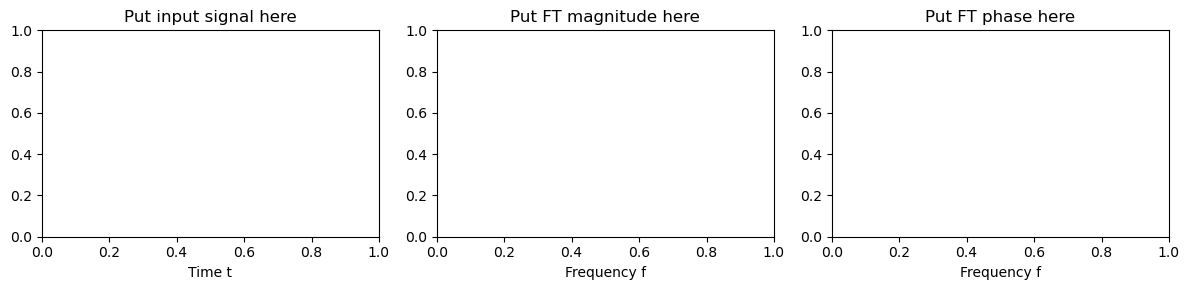

In [23]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

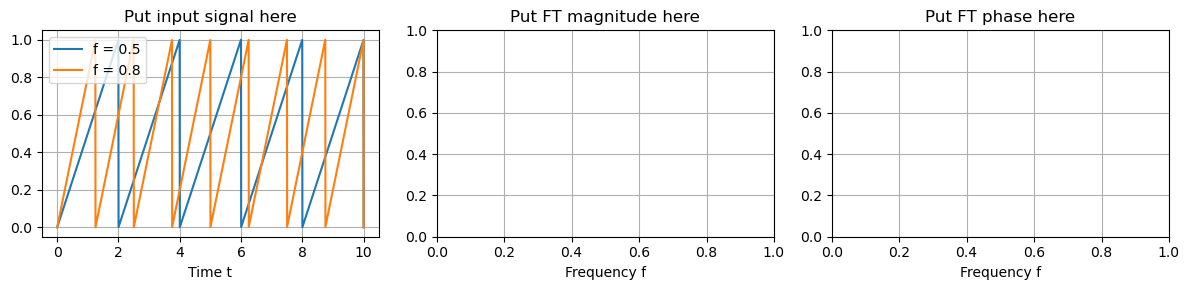

In [24]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
ax_t, ax_f, ax_p = axs

t = np.linspace(0, 10, 2048)
f = 0.5 # Frequency
T = 1/(f) # Period
f2 = 0.8 # Frequency
T2 = 1/(f2) # Period


ax_t.set_title("Put input signal here")
ax_t.set_xlabel("Time t")
ax_t.plot(t, (t%T)/T, label="f = 0.5")
ax_t.plot(t, (t%T2)/T2, label="f = 0.8")
ax_t.legend()
#....
ax_f.set_title("Put FT magnitude here")
ax_f.set_xlabel("Frequency f")
#....
ax_p.set_title("Put FT phase here")
ax_p.set_xlabel("Frequency f")
#...


for ax in axs:
    ax.grid(True)
fig.tight_layout()

## 1-D convolution

In [25]:
a = [1,1,1,0,0,0,0,1,1,1,0,0,0,1,0,0,0,1,1,1,0,1,1,0,0,0,0]
v = [1,1,1]



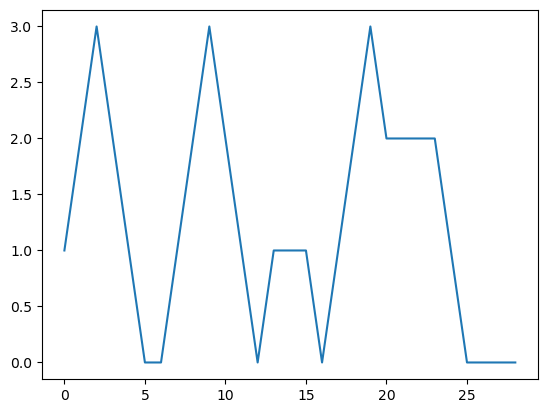

In [26]:
plt.plot(np.arange(len(np.convolve(a,v, mode='full'))), np.convolve(a,v, mode='full'))

### Convolution attempt (bringing circuits analogy) 

In [27]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
N = 500
t = np.linspace(0, 1, N, endpoint=False)
t_input = np.linspace(0, 5, N*5, endpoint=False)
signal_freq = 5
# dt = t[1] - t[0]
# nonsinu_signal = signal.square(2 * np.pi * signal_freq * t)

In [28]:
tau = 0.1
h_t = np.exp(-t/tau)
input_signal = signal.square(2 * np.pi * signal_freq * t_input) #cont_signal(t, freq)

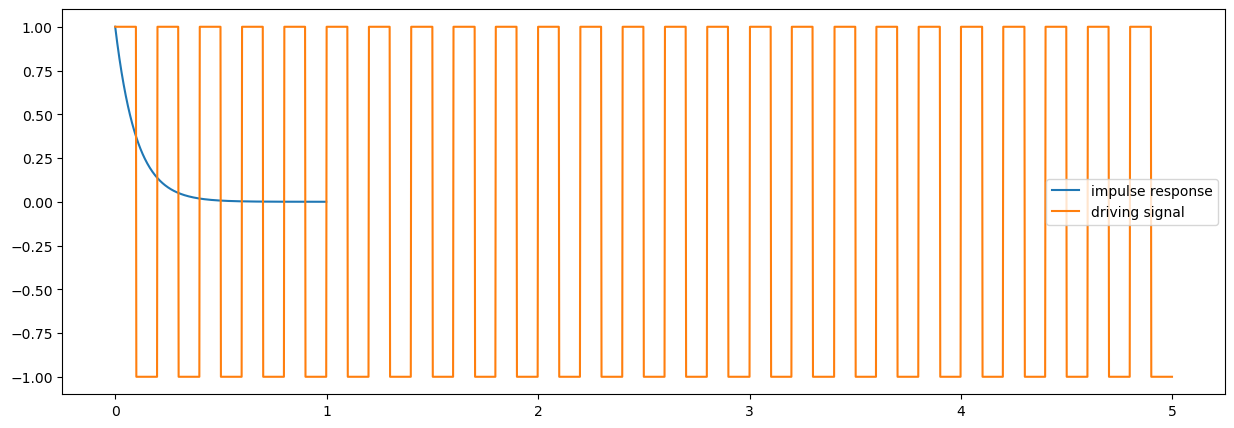

In [29]:
fig, ax = plt.subplots(figsize = (15,5))
ax.plot(t, h_t, label = "impulse response")
ax.plot(t_input, input_signal, label= "driving signal")
ax.legend()

In [30]:
response = np.convolve(input_signal, h_t, mode = "same")

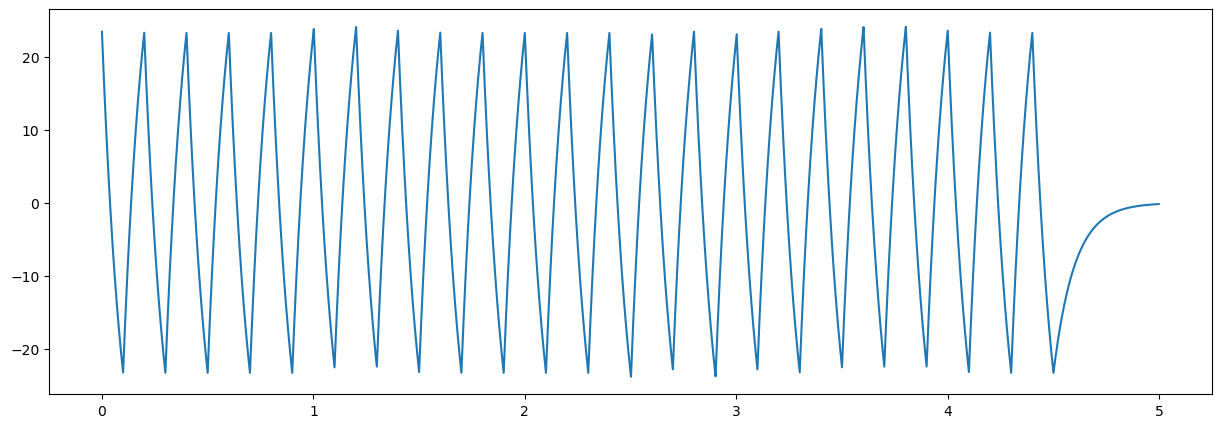

In [31]:
fig, ax = plt.subplots(figsize = (15,5))
#ax.plot(t, input_signal)
ax.plot(t_input, response)

In [32]:
fourier_length = len(h_t) + len(input_signal) - 1

In [33]:
fourier_input = np.fft.fft(input_signal, n = fourier_length)
fourier_h = np.fft.fft(h_t, n = fourier_length)

In [34]:
fourier_response = fourier_h*fourier_input 

In [35]:
response = np.real(np.fft.ifft(fourier_response))

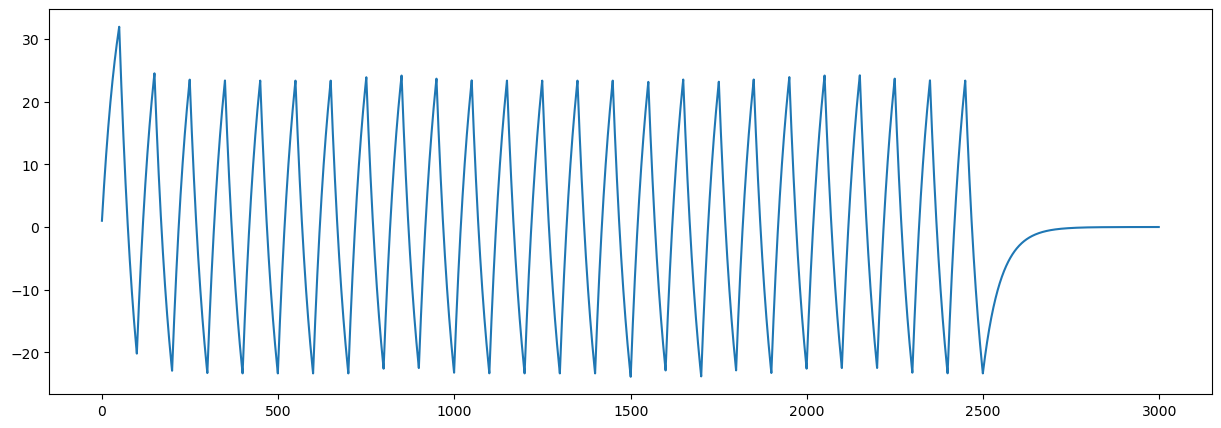

In [36]:
fig, ax = plt.subplots(figsize = (15,5))

ax.plot(response)